# DPT Pseudotime — HSC compartment\n\nDiffusion Pseudotime (Haghverdi et al. 2016) orders cells along a differentiation\ntrajectory by computing geodesic distances in diffusion space from a fixed root cell.\n\n**Root cell:** `Rx_4_AAGGACTAGGTGAACG-1`\n\n**Sections**\n1. Load + diffusion map\n2. Diffusion map visualisation\n3. Set root cell\n4. Run DPT\n5. DPT on UMAP\n6. Per-cluster DPT distributions\n7. Per-condition comparison\n8. Save outputs

In [26]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

matplotlib.rcParams['figure.dpi'] = 120
sc.settings.verbosity = 1

H5AD      = Path('output/objects/hsc.h5ad')
OUT       = Path('output/objects/dpt')
OUT.mkdir(parents=True, exist_ok=True)

CLUST_COL = 'sNN_pca.SCT_30_res.0.9'

COND_MAP = {
    'HSC_WT_CD41+'      : 'WT',
    'HSC_Het_CD41+mCh-' : 'mCh-',
    'HSC_Het_CD41+mCh+' : 'mCh+',
}
COND_ORDER  = ['WT', 'mCh-', 'mCh+']
COND_COLORS = {'WT': '#1f78b4', 'mCh-': '#a6cee3', 'mCh+': '#e31a1c'}

ROOT_BARCODE = 'Rx_4_AAGGACTAGGTGAACG-1'

## 1 · Load + diffusion map

DPT requires a diffusion map (`sc.tl.diffmap`). We rebuild the kNN graph
from the stored PCA (50 PCs, 30 neighbours — same as pipeline) then compute
the top 15 diffusion components.

In [27]:
adata = sc.read_h5ad(H5AD)
adata.obs['condition'] = adata.obs['sample.name'].map(COND_MAP).astype('category')
adata.obs[CLUST_COL]   = adata.obs[CLUST_COL].astype(str).astype('category')

print(adata)
print()
print(adata.obs.groupby('condition').size().rename('n_cells'))

# ── Graph strategy ────────────────────────────────────────────────────────────
# The h5ad carries the Seurat SNN/KNN graphs exported from the pipeline
# (obsp['connectivities'] = SNN, obsp['distances'] = KNN).
# If present we register them; otherwise recompute from X_pca.
PIPELINE_GRAPH = 'connectivities' in adata.obsp
print(f'\nobsp keys: {list(adata.obsp.keys())}')

if PIPELINE_GRAPH:
    # Infer actual k from the KNN distances edge count
    if 'distances' in adata.obsp:
        k_pipeline = int(adata.obsp['distances'].nnz / adata.n_obs)
        print(f'[graph] distances: {adata.obsp["distances"].nnz:,} edges  →  k = {k_pipeline}')
    else:
        k_pipeline = 30
        print(f'[graph] No distances matrix — assuming k={k_pipeline}')

    GRAPH_LABEL = f'Pipeline SNN (Seurat, k={k_pipeline})'
    print(f'[graph] Using pipeline graph from obsp["connectivities"]  ({GRAPH_LABEL})')

    adata.uns['neighbors'] = {
        'connectivities_key': 'connectivities',
        'distances_key':      'distances' if 'distances' in adata.obsp else None,
        'params': {'n_neighbors': k_pipeline, 'method': 'seurat_snn', 'n_pcs': 50}
    }
else:
    k_pipeline = 30
    GRAPH_LABEL = f'Recomputed kNN (scanpy, k={k_pipeline})'
    print(f'[graph] Pipeline graph not found — recomputing kNN  ({GRAPH_LABEL})')
    sc.pp.neighbors(adata, n_neighbors=k_pipeline, n_pcs=50,
                    use_rep='X_pca', random_state=42)

sc.tl.diffmap(adata, n_comps=15)
print('Diffusion map computed:', adata.obsm['X_diffmap'].shape)


AnnData object with n_obs × n_vars = 50056 × 11057
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'cell.name', 'tube', 'sample.name', 'sample.name.long', 'compartment', 'nCount_HTO', 'nFeature_HTO', 'percent.mt', 'percent.rp', 'percent.hb', 'count_feat_ratio', 'percent.stress', 'S.Score', 'G2M.Score', 'Phase', 'dm2_max_prop', 'dm2_max_resid', 'dm2_class', 'pass_mt', 'pass_nFeature', 'pass_rp', 'pass_hb', 'pass_qc', 'pass_hto', 'scDblFinder.score', 'scDblFinder.class', 'pass_dbl', 'pass_cell', 'nCount_SCT', 'nFeature_SCT', 'sNN_pca.SCT_30_res.0.1', 'sNN_pca.SCT_30_res.0.3', 'sNN_pca.SCT_30_res.0.5', 'sNN_pca.SCT_30_res.0.7', 'sNN_pca.SCT_30_res.0.9', 'sNN_pca.SCT_30_res.1', 'sNN_pca.SCT_30_res.1.2', 'sNN_pca.SCT_30_res.1.3', 'sNN_pca.SCT_30_res.1.5', 'seurat_clusters', 'cytotrace2_score', 'cytotrace2_potency', 'cytotrace2_relative', 'condition'
    obsm: 'X_pca', 'X_umap'
    obsp: 'connectivities', 'distances'

condition
WT      16511
mCh+    15840
mCh-    17705
Name: n_cells, dt

In [29]:
adata.obsp['connectivities']

<Compressed Sparse Column sparse matrix of dtype 'float64'
	with 5587496 stored elements and shape (50056, 50056)>

## 1a · Graph comparison

Compare diffusion map computed on the **pipeline SNN** (Seurat) vs **recomputed kNN** (scanpy, same k).
The pipeline SNN is the graph used for all clustering and UMAP — using it for DPT ensures trajectory ordering
is consistent with the same connectivity. The alt graph uses the same k but a different algorithm (scanpy kNN)
to isolate the effect of graph construction on DPT ordering.

In [ ]:
# ── Alt graph: recomputed scanpy kNN with same k as the pipeline graph ────────
# Main adata already uses the pipeline graph (set in the loading cell).
# Alt adata always recomputes with scanpy kNN — same k, different algorithm —
# to isolate the effect of graph construction on DPT ordering.
adata_alt = adata.copy()
sc.pp.neighbors(adata_alt, n_neighbors=k_pipeline, n_pcs=50,
                use_rep='X_pca', random_state=42)

main_label = GRAPH_LABEL
alt_label  = f'Recomputed kNN (scanpy, k={k_pipeline})'

print(f'Main graph : {main_label}')
print(f'Alt  graph : {alt_label}')
if PIPELINE_GRAPH:
    print(f'obsp keys used by main: {list(adata.obsp.keys())}')

sc.tl.diffmap(adata_alt, n_comps=15)

# Set root on alt adata before DPT — same barcode, same obs_names
assert ROOT_BARCODE in adata_alt.obs_names
adata_alt.uns['iroot'] = int(adata_alt.obs_names.get_loc(ROOT_BARCODE))
sc.tl.dpt(adata_alt, n_dcs=15)

# Set root on main adata and run DPT
assert ROOT_BARCODE in adata.obs_names
root_idx = int(adata.obs_names.get_loc(ROOT_BARCODE))
adata.uns['iroot'] = root_idx
sc.tl.dpt(adata, n_dcs=15)

umap = adata.obsm['X_umap']
rng  = np.random.default_rng(42)
samp = rng.choice(len(umap), size=min(15_000, len(umap)), replace=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle('Diffusion map & DPT pseudotime — graph comparison',
             fontsize=13, fontweight='bold')

for row, (ad, label) in enumerate([(adata, main_label), (adata_alt, alt_label)]):
    dpt_vals = ad.obs['dpt_pseudotime'].values
    dm       = ad.obsm['X_diffmap']

    # DC1 vs DC2 (condition)
    ax = axes[row, 0]
    for c in COND_ORDER:
        mask = ad.obs['condition'].values[samp] == c
        ax.scatter(dm[samp[mask], 1], dm[samp[mask], 2],
                   c=COND_COLORS[c], s=1, alpha=0.4, label=c, rasterized=True)
    ax.set_xlabel('DC1'); ax.set_ylabel('DC2')
    ax.set_title(f'{label}\nDC1 vs DC2 (condition)', fontsize=8)
    if row == 0: ax.legend(markerscale=5, frameon=False, fontsize=7)
    ax.tick_params(labelsize=6)

    # DC1 vs DC2 (DPT)
    ax = axes[row, 1]
    order = np.argsort(dpt_vals[samp])
    sc2 = ax.scatter(dm[samp[order], 1], dm[samp[order], 2],
                     c=dpt_vals[samp[order]], cmap='viridis',
                     s=1, alpha=0.5, rasterized=True)
    plt.colorbar(sc2, ax=ax, label='DPT')
    ax.set_xlabel('DC1'); ax.set_ylabel('DC2')
    ax.set_title(f'{label}\nDC1 vs DC2 (DPT)', fontsize=8)
    ax.tick_params(labelsize=6)

    # DPT on UMAP
    ax = axes[row, 2]
    order_u = np.argsort(dpt_vals)
    sc3 = ax.scatter(umap[order_u, 0], umap[order_u, 1],
                     c=dpt_vals[order_u], cmap='viridis',
                     s=0.3, alpha=0.6, rasterized=True)
    plt.colorbar(sc3, ax=ax, label='DPT')
    ax.set_title(f'{label}\nDPT on UMAP', fontsize=8)
    ax.axis('off')

plt.tight_layout()
out_path = OUT / 'dpt_graph_comparison.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()

# Spearman correlation between the two DPT vectors
from scipy.stats import spearmanr
rho, pval = spearmanr(adata.obs['dpt_pseudotime'],
                       adata_alt.obs['dpt_pseudotime'])
print(f'\nSpearman correlation between DPT vectors: ρ = {rho:.3f}  (p = {pval:.2e})')
print('(ρ close to 1 = similar ordering regardless of graph)')

# ── Preserve kNN diffmap before freeing adata_alt ────────────────────────────
# Stored as plain arrays so section 1b can plot and the save cell can write CSV.
diffmap_knn  = adata_alt.obsm['X_diffmap'].copy()   # (n_cells, n_comps)
cond_knn     = adata_alt.obs['condition'].values.copy()
clust_knn    = adata_alt.obs[CLUST_COL].astype(str).values.copy()

del adata_alt
import gc; gc.collect()


## 1b · Diffusion map visualisation\n\nDiffusion components (DCs) capture the major axes of variation in the\ndiffusion-space graph. DC1 typically aligns with the main differentiation\naxis; higher DCs capture branching or secondary gradients.\n\n- **Top panel:** DC1–DC4 pairwise scatter coloured by CytoTRACE2 score\n- **Middle panel:** same pairs coloured by condition\n- **Bottom panel:** same pairs coloured by cluster

In [ ]:
dm     = adata.obsm['X_diffmap']
cond   = adata.obs['condition'].values
clust  = adata.obs[CLUST_COL].astype(str).values

PAIRS = [(1, 2), (1, 3), (2, 3), (1, 4)]
n_pairs = len(PAIRS)

rng  = np.random.default_rng(42)
samp = rng.choice(dm.shape[0], size=min(15_000, dm.shape[0]), replace=False)

# ── Condition ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, n_pairs, figsize=(n_pairs * 4.5, 4))
fig.suptitle('Diffusion map — coloured by condition', fontsize=12, fontweight='bold')
for ax, (a, b) in zip(axes, PAIRS):
    for c in COND_ORDER:
        mask = cond[samp] == c
        ax.scatter(dm[samp[mask], a], dm[samp[mask], b],
                   c=COND_COLORS[c], s=1.5, alpha=0.5, label=c, rasterized=True)
    ax.set_xlabel(f'DC{a}', fontsize=9); ax.set_ylabel(f'DC{b}', fontsize=9)
    ax.set_title(f'DC{a} vs DC{b}', fontsize=9); ax.tick_params(labelsize=7)
axes[-1].legend(markerscale=5, frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(OUT / 'diffmap_condition.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Cluster ──────────────────────────────────────────────────────────────────
uniq_clust  = sorted(set(clust), key=lambda x: int(x))
cmap_clust  = plt.cm.get_cmap('tab20', len(uniq_clust))
clust_color = {c: cmap_clust(i) for i, c in enumerate(uniq_clust)}

fig, axes = plt.subplots(1, n_pairs, figsize=(n_pairs * 4.5, 4))
fig.suptitle('Diffusion map — coloured by cluster', fontsize=12, fontweight='bold')
for ax, (a, b) in zip(axes, PAIRS):
    colors = [clust_color[c] for c in clust[samp]]
    ax.scatter(dm[samp, a], dm[samp, b], c=colors, s=1.5, alpha=0.5, rasterized=True)
    ax.set_xlabel(f'DC{a}', fontsize=9); ax.set_ylabel(f'DC{b}', fontsize=9)
    ax.set_title(f'DC{a} vs DC{b}', fontsize=9); ax.tick_params(labelsize=7)
handles = [plt.Line2D([0],[0], marker='o', color='w',
                       markerfacecolor=clust_color[c], markersize=6, label=c)
           for c in uniq_clust]
axes[-1].legend(handles=handles, title='Cluster', fontsize=7,
                bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
plt.tight_layout()
fig.savefig(OUT / 'diffmap_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

print('Saved diffmap_condition.png / diffmap_cluster.png')

### Recomputed kNN diffusion map

In [ ]:
rng_knn  = np.random.default_rng(42)
samp_knn = rng_knn.choice(diffmap_knn.shape[0],
                           size=min(15_000, diffmap_knn.shape[0]), replace=False)

# ── Condition ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, n_pairs, figsize=(n_pairs * 4.5, 4))
fig.suptitle(f'Diffusion map — {alt_label} — coloured by condition',
             fontsize=12, fontweight='bold')
for ax, (a, b) in zip(axes, PAIRS):
    for c in COND_ORDER:
        mask = cond_knn[samp_knn] == c
        ax.scatter(diffmap_knn[samp_knn[mask], a], diffmap_knn[samp_knn[mask], b],
                   c=COND_COLORS[c], s=1.5, alpha=0.5, label=c, rasterized=True)
    ax.set_xlabel(f'DC{a}', fontsize=9); ax.set_ylabel(f'DC{b}', fontsize=9)
    ax.set_title(f'DC{a} vs DC{b}', fontsize=9); ax.tick_params(labelsize=7)
axes[-1].legend(markerscale=5, frameon=False, fontsize=8)
plt.tight_layout()
fig.savefig(OUT / 'diffmap_knn_condition.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Cluster ──────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, n_pairs, figsize=(n_pairs * 4.5, 4))
fig.suptitle(f'Diffusion map — {alt_label} — coloured by cluster',
             fontsize=12, fontweight='bold')
for ax, (a, b) in zip(axes, PAIRS):
    colors = [clust_color[c] for c in clust_knn[samp_knn]]
    ax.scatter(diffmap_knn[samp_knn, a], diffmap_knn[samp_knn, b],
               c=colors, s=1.5, alpha=0.5, rasterized=True)
    ax.set_xlabel(f'DC{a}', fontsize=9); ax.set_ylabel(f'DC{b}', fontsize=9)
    ax.set_title(f'DC{a} vs DC{b}', fontsize=9); ax.tick_params(labelsize=7)
axes[-1].legend(handles=handles, title='Cluster', fontsize=7,
                bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
plt.tight_layout()
fig.savefig(OUT / 'diffmap_knn_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Saved: diffmap_knn_condition.png / diffmap_knn_cluster.png')


In [ ]:
# Root is already set in the graph comparison cell.
# This confirms the root cell info and which graph is used downstream.
root_obs = adata.obs.iloc[root_idx]
print(f'Root cell   : {ROOT_BARCODE}')
print(f'  index     : {root_idx}')
print(f'  condition : {root_obs["condition"]}')
print(f'  cluster   : {root_obs[CLUST_COL]}')
print(f'  graph     : {main_label}  ← used for all downstream analysis')


## 3 · Run DPT

In [ ]:
# DPT was already computed on the SNN graph in the graph comparison section.
# Re-running here is idempotent and confirms the values used downstream.
sc.tl.dpt(adata, n_dcs=15)
print(f'Graph       : {main_label}')
print(f'DPT range   : {adata.obs["dpt_pseudotime"].min():.4f} — {adata.obs["dpt_pseudotime"].max():.4f}')
if 'dpt_groups' in adata.obs.columns:
    print('Cells per branch:')
    print(adata.obs['dpt_groups'].value_counts())
else:
    print('dpt_groups not available (run sc.tl.paga first to get branch assignments)')


## 4 · DPT on UMAP

In [ ]:
umap = adata.obsm['X_umap']
dpt  = adata.obs['dpt_pseudotime'].values
cond = adata.obs['condition'].values
dm   = adata.obsm['X_diffmap']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'DPT pseudotime & diffusion components — {main_label}',
             fontsize=12, fontweight='bold')

# ── DC1 (first non-trivial diffusion component) ───────────────────────────────
dc1 = dm[:, 1]
vabs = np.percentile(np.abs(dc1), 99)   # symmetric clip at 99th pctile
order_dc = np.argsort(dc1)
sc_dc = axes[0].scatter(umap[order_dc, 0], umap[order_dc, 1],
                         c=dc1[order_dc], cmap='RdBu_r',
                         vmin=-vabs, vmax=vabs,
                         s=0.3, alpha=0.7, rasterized=True)
plt.colorbar(sc_dc, ax=axes[0], label='DC1')
axes[0].scatter(*umap[root_idx], c='lime', s=120, zorder=6,
                marker='*', label='root', linewidths=0.5, edgecolors='black')
axes[0].set_title('DC1 — top diffusion component', fontweight='bold')
axes[0].legend(markerscale=1, frameon=False, fontsize=8)
axes[0].axis('off')

# ── DPT pseudotime ────────────────────────────────────────────────────────────
order = np.argsort(dpt)
sc_dpt = axes[1].scatter(umap[order, 0], umap[order, 1],
                          c=dpt[order], cmap='viridis',
                          s=0.3, alpha=0.7, rasterized=True)
plt.colorbar(sc_dpt, ax=axes[1], label='DPT pseudotime')
axes[1].scatter(*umap[root_idx], c='lime', s=120, zorder=6,
                marker='*', linewidths=0.5, edgecolors='black')
axes[1].set_title('DPT pseudotime', fontweight='bold')
axes[1].axis('off')

# ── Condition ─────────────────────────────────────────────────────────────────
for c in COND_ORDER:
    mask = cond == c
    axes[2].scatter(umap[mask, 0], umap[mask, 1],
                    c=COND_COLORS[c], s=0.3, alpha=0.5, label=c, rasterized=True)
axes[2].legend(markerscale=6, frameon=False)
axes[2].set_title('Condition', fontweight='bold')
axes[2].axis('off')

plt.tight_layout()
out_path = OUT / 'dpt_umap.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()


## 6 · Per-cluster DPT distribution

/tmp/ipykernel_96145/1645112355.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


Saved: /project/output/dpt/dpt_per_cluster.png


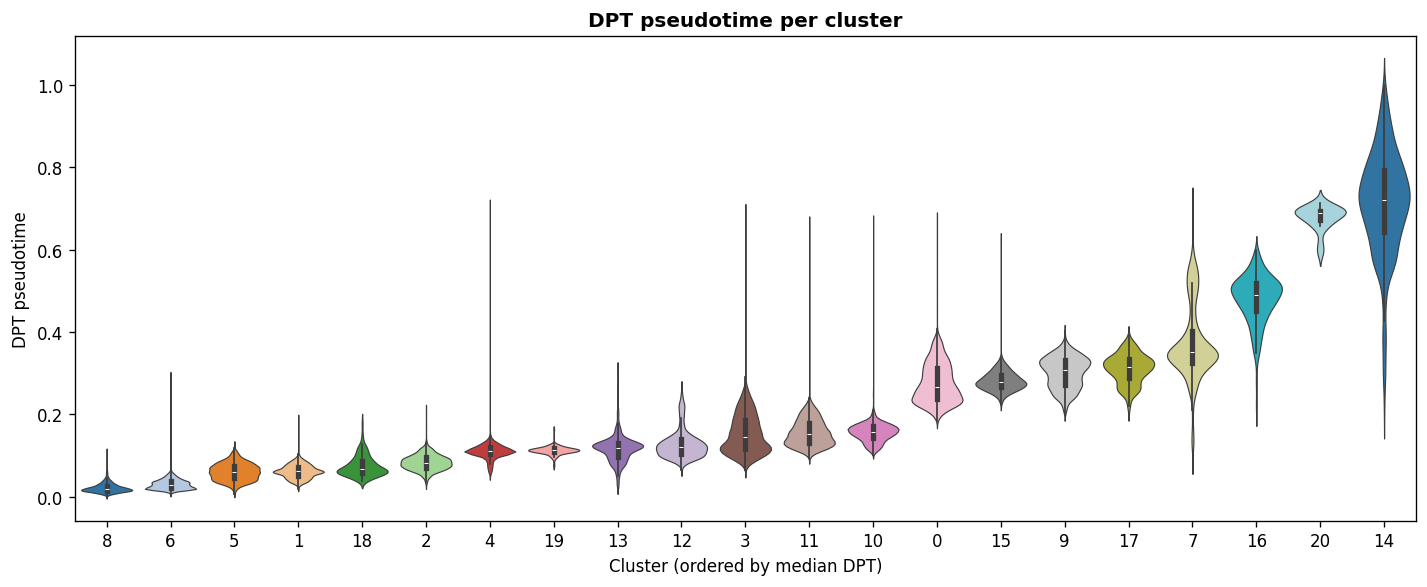

In [7]:
clust_order = (
    adata.obs.groupby(CLUST_COL)['dpt_pseudotime']
    .median()
    .sort_values()
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(
    data    = adata.obs,
    x       = CLUST_COL,
    y       = 'dpt_pseudotime',
    order   = clust_order,
    inner   = 'box',
    palette = 'tab20',
    linewidth = 0.7,
    ax      = ax,
)
ax.set_xlabel('Cluster (ordered by median DPT)')
ax.set_ylabel('DPT pseudotime')
ax.set_title('DPT pseudotime per cluster', fontweight='bold')
plt.tight_layout()
out_path = OUT / 'dpt_per_cluster.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()

## 7 · Per-condition comparison

DPT distributions split by condition — shifts indicate altered developmental
progression between WT / mCh− / mCh+.

Saved: /project/output/dpt/dpt_per_condition.png


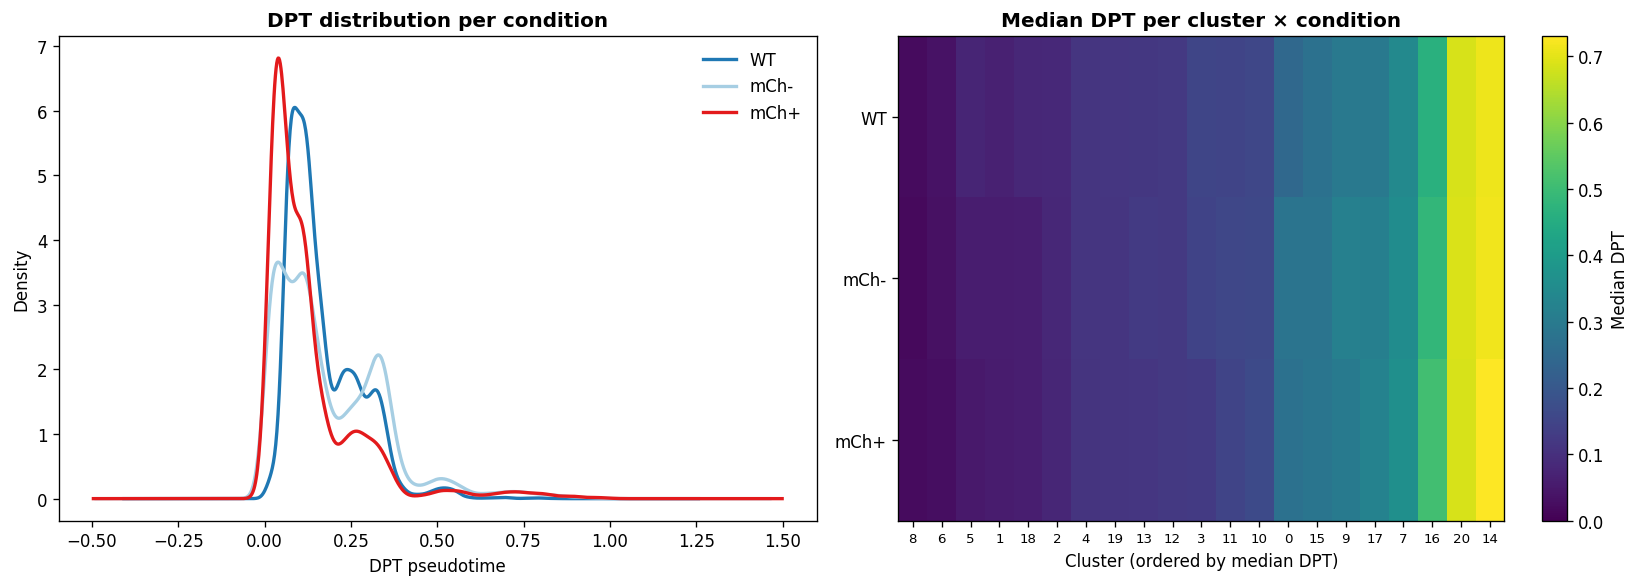

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Overall DPT density per condition
for c in COND_ORDER:
    vals = adata.obs.loc[adata.obs['condition'] == c, 'dpt_pseudotime']
    vals.plot.density(ax=axes[0], color=COND_COLORS[c], label=c, linewidth=2)
axes[0].set_xlabel('DPT pseudotime')
axes[0].set_ylabel('Density')
axes[0].set_title('DPT distribution per condition', fontweight='bold')
axes[0].legend(frameon=False)

# Per-cluster × condition median DPT heatmap
heat = (
    adata.obs
    .groupby([CLUST_COL, 'condition'])['dpt_pseudotime']
    .median()
    .unstack('condition')
    [COND_ORDER]
    .loc[clust_order]          # ordered by overall median DPT
)
im = axes[1].imshow(heat.T, aspect='auto', cmap='viridis',
                    vmin=0, vmax=heat.values.max())
plt.colorbar(im, ax=axes[1], label='Median DPT')
axes[1].set_xticks(range(len(clust_order)))
axes[1].set_xticklabels(clust_order, fontsize=8)
axes[1].set_yticks(range(len(COND_ORDER)))
axes[1].set_yticklabels(COND_ORDER)
axes[1].set_xlabel('Cluster (ordered by median DPT)')
axes[1].set_title('Median DPT per cluster × condition', fontweight='bold')

plt.tight_layout()
out_path = OUT / 'dpt_per_condition.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'Saved: {out_path}')
plt.show()

## 8 · Save outputs

In [ ]:
import re

def graph_file_tag(label):
    """Sanitise a graph label into a filesystem-safe tag."""
    return re.sub(r'[^a-z0-9]+', '_', label.lower()).strip('_')

main_tag = graph_file_tag(main_label)   # e.g. pipeline_snn_seurat_k_30
alt_tag  = graph_file_tag(alt_label)    # e.g. recomputed_knn_scanpy_k_30

# ── DPT cell table (SNN-based DPT used for downstream) ───────────────────────
keep_cols = ['sample.name', 'condition', CLUST_COL, 'dpt_pseudotime']
if 'dpt_groups' in adata.obs.columns:
    keep_cols.append('dpt_groups')

cell_tbl = adata.obs[keep_cols].copy()
cell_tbl.columns = [c.replace('.', '_').replace('+', 'pos').replace('-', 'neg')
                    for c in keep_cols]
out_csv = OUT / f'dpt_cell_table_{main_tag}.csv'
cell_tbl.to_csv(out_csv)
print(f'Saved: {out_csv}  ({len(cell_tbl):,} rows)')

# ── Diffusion components — SNN graph (pipeline, used downstream) ──────────────
n_dc = adata.obsm['X_diffmap'].shape[1]
dc_snn = pd.DataFrame(
    adata.obsm['X_diffmap'],
    index   = adata.obs_names,
    columns = [f'DC{i}' for i in range(n_dc)]
)
dc_snn.index.name = 'cell_id'
out_snn = OUT / f'diffmap_components_{main_tag}.csv'
dc_snn.to_csv(out_snn)
print(f'Saved: {out_snn}  ({n_dc} components × {len(dc_snn):,} cells)')

# ── Diffusion components — recomputed kNN graph (comparison) ─────────────────
dc_knn = pd.DataFrame(
    diffmap_knn,
    index   = adata.obs_names,
    columns = [f'DC{i}' for i in range(diffmap_knn.shape[1])]
)
dc_knn.index.name = 'cell_id'
out_knn = OUT / f'diffmap_components_{alt_tag}.csv'
dc_knn.to_csv(out_knn)
print(f'Saved: {out_knn}  ({diffmap_knn.shape[1]} components × {len(dc_knn):,} cells)')

print(f'\nNote: DC0 is the trivial stationary component; DC1–DC{n_dc-1} are the informative axes.')
print(f'Use {out_snn.name} in R for DimReduc — consistent with the pipeline graph.')

# ── Full AnnData ──────────────────────────────────────────────────────────────
import anndata as _ad
_ad.settings.allow_write_nullable_strings = True

out_h5ad = OUT / 'hsc_dpt.h5ad'
adata.write_h5ad(out_h5ad)
print(f'Saved: {out_h5ad}')
